# Symmetric NMR transfer comparison at N100

Direct training, full fine-tuning and rank-4 ELoRA. Analysis: 6 November 2026.

Compare prediction of the scalar (`0e`) and symmetric traceless (`2e`, angular order l = 2) parts separately. All methods use the same N100 structures, 50 validation structures, six-coefficient target and balanced loss. The transfer source was trained on 800 E/F-labelled structures; the NMR fitting budget is 100. Fixed loss normalisers use the full 800-structure NMR training pool, as in Experiment 01; model scales/offsets are fitted on N100. The learning-rate presets are 3e-3 for direct training, 1e-4 for full fine-tuning and 3e-3 for ELoRA.

In [1]:
from pathlib import Path
import json
import sys
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'nmr_helpers').is_dir())
sys.path.insert(0, str(ROOT))
from analysis_helpers.symmetric_transfer_review import (
    RUNS, LABELS, PANELS, evaluate, load_review, load_cache, history,
    plot_run_history, plot_parity, plot_learning_comparison,
    plot_error_comparison, plot_anisotropic_parity, plot_feature_change, save_figure,
)
DATA = ROOT / 'experiments/symmetric-transfer-N100-data'
# This recomputes unmodified best-model predictions; it does not train models.
RECOMPUTE = False
if RECOMPUTE:
    evaluate(ROOT, DATA, DATA)
manifest, scores = load_review(ROOT, DATA)
audits = manifest['runs']
pd.set_option('display.max_columns', 14)
pd.set_option('display.precision', 4)
print('Matched N100 training structures, 50 validation structures and 150 held-out test structures.')
print('Exports match best.ckpt exactly; original checkpoints and datasets are unchanged.')

FIGURES = DATA / 'figures'


Matched N100 training structures, 50 validation structures and 150 held-out test structures.
Exports match best.ckpt exactly; original checkpoints and datasets are unchanged.


## Run selection and fitting

All three runs reached the configured early-stopping patience of 300. Select by minimum balanced validation loss, then evaluate the unmodified exports on training, validation and held-out test data. Time excludes the earlier E/F pretraining. The throughput statistic uses the common epoch window 6–100 on L40S. Epoch timing includes validation and checkpoint/export overhead; logged training-batch duration is shown separately. Direct training and full fine-tuning attempted LAMMPS exports at each new best checkpoint; ELoRA disabled that optional export after its unsupported scripting attempt. The timings compare the actual training recipes.

In [2]:
rows = []
for label, a in audits.items():
    rows.append({'Method': LABELS[label], 'Best / last epoch': f"{a['best_epoch']} / {a['last_epoch']}",
        'Trainable parameters': a['trainable_parameters'], 'Initial LR': a['initial_lr'],
        'Train loss': a['train_balanced_loss_cpu'], 'Validation loss': a['validation_balanced_loss_cpu'],
        'Test loss': a['test_balanced_loss_cpu'], 'Minutes to best': a['minutes_to_best'],
        'Median seconds/epoch (6–100)': a['median_seconds_per_epoch_6_to_100'],
        'Logged ms/train batch (6–100)': a['median_logged_ms_per_training_batch_6_to_100']})
display(pd.DataFrame(rows).set_index('Method'))


,Best / last epoch,Trainable parameters,Initial LR,Train loss,Validation loss,Test loss,Minutes to best,Median seconds/epoch (6–100),Logged ms/train batch (6–100)
Method,,,,,,,,,
Direct training,109 / 409,2984582,0.0030,0.0021,0.0419,0.0253,27.1369,14.1371,112.0
Full fine-tuning,348 / 648,2984582,0.0001,0.0034,0.0436,0.0203,85.4940,14.9878,112.0
ELoRA,198 / 498,79622,0.0030,0.0047,0.0274,0.0159,27.4476,8.1740,46.0


## Soprano NMR parameter comparison

The main NMR-facing comparison now uses isotropic shielding σiso, signed Haeberlen anisotropy Δσ and asymmetry η. These are extracted with Soprano from each predicted/DFT symmetric tensor; original checkpoint selection and training loss are retained. [The Soprano parameter report](SymmetricTensor-N100-Soprano-Parameters.ipynb) contains full parity plots and ordering diagnostics. ELoRA has the lowest anisotropy RMSE; full fine-tuning has the lowest asymmetry RMSE for Si and O. The signed anisotropy scores include opposite-sign predictions, so they must be read with the convention diagnostic. The tensor/component analyses below remain supporting checks, including orientation-sensitive accuracy.

,Method,Element,Parameter,Units,RMSE,MAE,R²
0,Direct training,Si,isotropy,ppm,1.5163,0.7378,0.9693
1,Direct training,Si,anisotropy,ppm,20.8414,7.1973,0.7640
2,Direct training,Si,asymmetry,dimensionless,0.1374,0.0992,0.6655
3,Direct training,O,isotropy,ppm,3.0895,1.6401,0.9697
4,Direct training,O,anisotropy,ppm,18.3651,5.1662,0.6577
5,Direct training,O,asymmetry,dimensionless,0.0978,0.0647,0.8024
6,Full fine-tuning,Si,isotropy,ppm,1.0501,0.5753,0.9853
7,Full fine-tuning,Si,anisotropy,ppm,20.6055,6.2903,0.7693
8,Full fine-tuning,Si,asymmetry,dimensionless,0.1184,0.0844,0.7516
9,Full fine-tuning,O,isotropy,ppm,2.5901,1.3808,0.9787


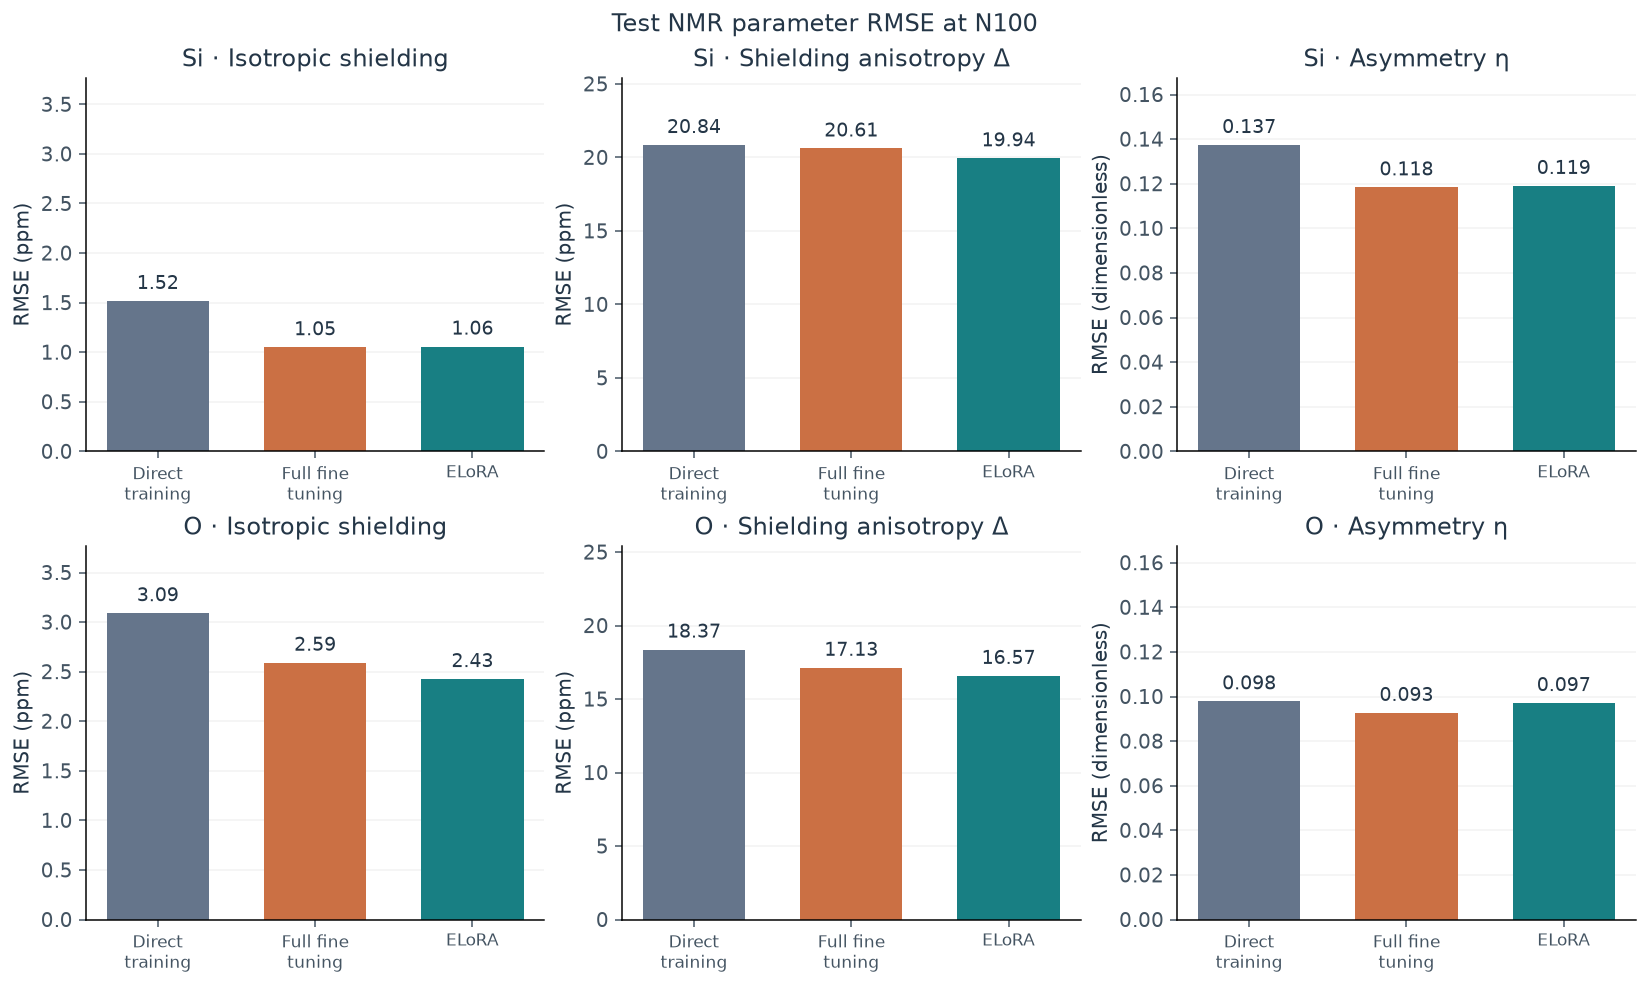

In [9]:
from analysis_helpers.nmr_parameters import load_parameter_metrics, prepare_parameters, plot_parameter_rmse, PARAMETERS
if RECOMPUTE:
    prepare_parameters(ROOT)
parameter_metrics = load_parameter_metrics(ROOT)
display(parameter_metrics[(parameter_metrics.Split == 'test') & parameter_metrics.Parameter.isin(PARAMETERS)][['Method','Element','Parameter','Units','RMSE','MAE','R2']].rename(columns={'R2':'R²'}).reset_index(drop=True))
fig = plot_parameter_rmse(parameter_metrics, 'test')
save_figure(fig, DATA / 'nmr-parameters/figures', 'test-parameter-rmse')
plt.show()


## Scalar and tensor learning curves

Each line is the complete validation RMSE at that epoch; every method is evaluated on the same structures. These curves measure output learning. They do not by themselves isolate the contribution of the pretrained higher-order representation.

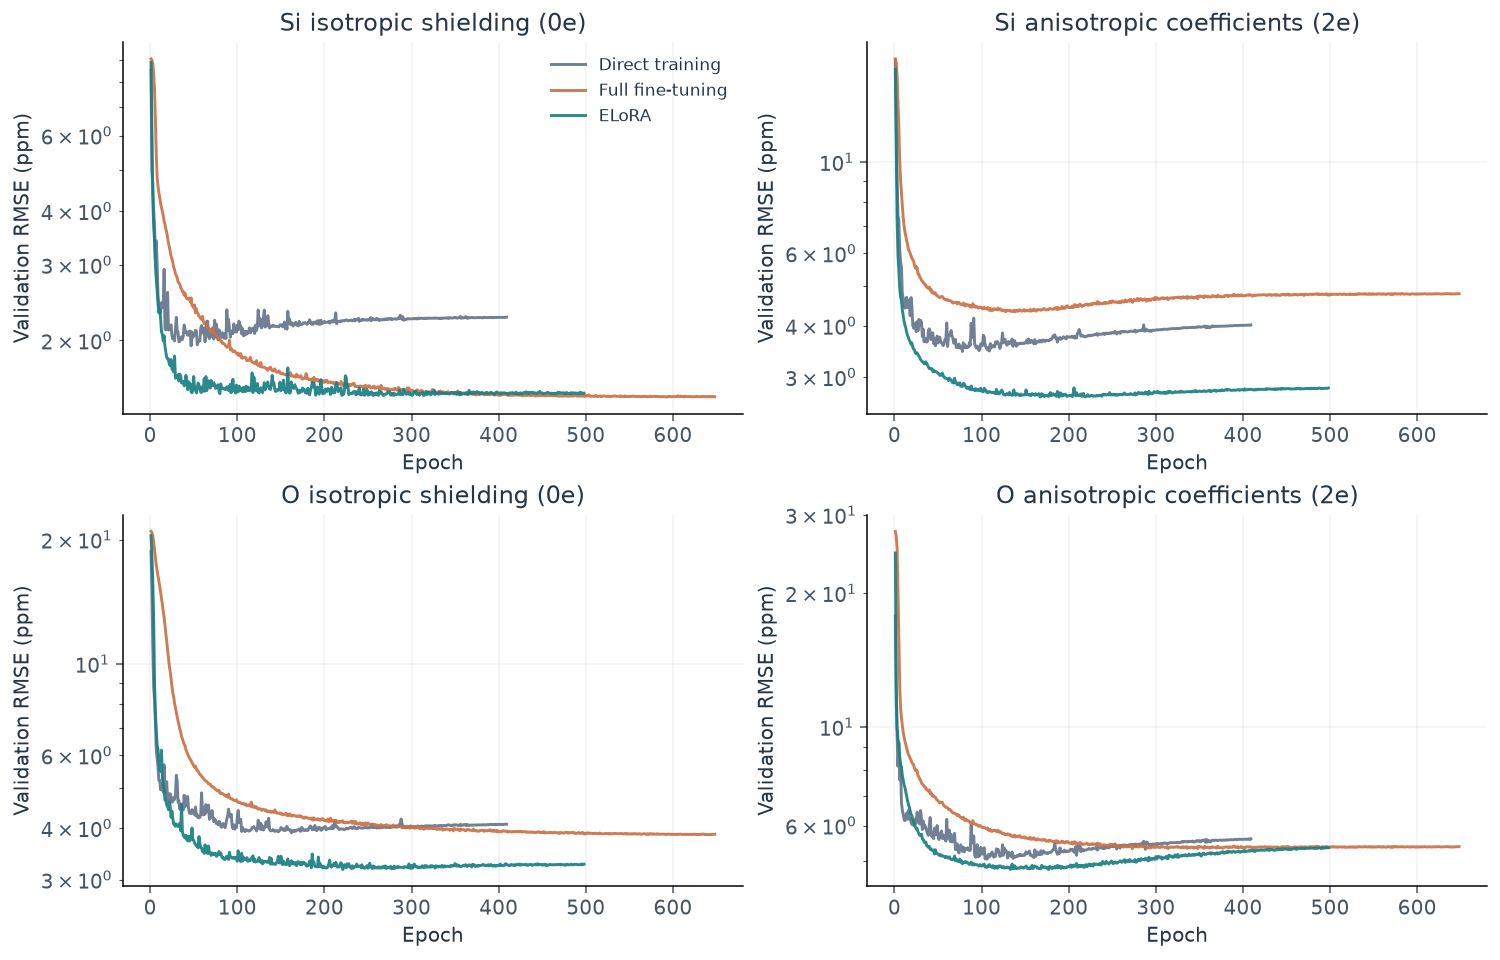

In [3]:
fig = plot_learning_comparison(DATA)
save_figure(fig, FIGURES, 'validation-learning-curves')
plt.show()


## Validation and held-out prediction accuracy

`0e` scores are converted to physical isotropic shieldings by dividing by √3. `2e` scores pool the five orthonormal traceless coefficients per atom. RMSE and MAE are in ppm. Anisotropic coefficient RMSE equals traceless-tensor Frobenius RMSE / √5, so it also measures tensor error independently of a common rotation of the coordinate frame. Component MAE and the pooled R² depend on their stated component convention.

,Method,Element,Block,Train RMSE,Validation RMSE,Test RMSE,Test MAE,Test R²
0,Direct training,Si,iso,0.3299,2.0601,1.5163,0.7378,0.9693
1,Direct training,Si,aniso,0.8453,3.4737,2.7716,1.6733,0.9733
2,Direct training,O,iso,0.8997,3.9233,3.0895,1.6401,0.9697
3,Direct training,O,aniso,1.4631,5.1026,4.1077,2.3899,0.9780
4,Full fine-tuning,Si,iso,0.3398,1.5006,1.0501,0.5753,0.9853
5,Full fine-tuning,Si,aniso,0.9860,4.6573,3.0416,1.4559,0.9679
6,Full fine-tuning,O,iso,1.1127,3.9394,2.5901,1.3808,0.9787
7,Full fine-tuning,O,aniso,2.1075,5.3236,3.9706,2.1869,0.9795
8,ELoRA,Si,iso,0.4553,1.5035,1.0562,0.5968,0.9851
9,ELoRA,Si,aniso,1.2003,2.6939,2.2369,1.3629,0.9826


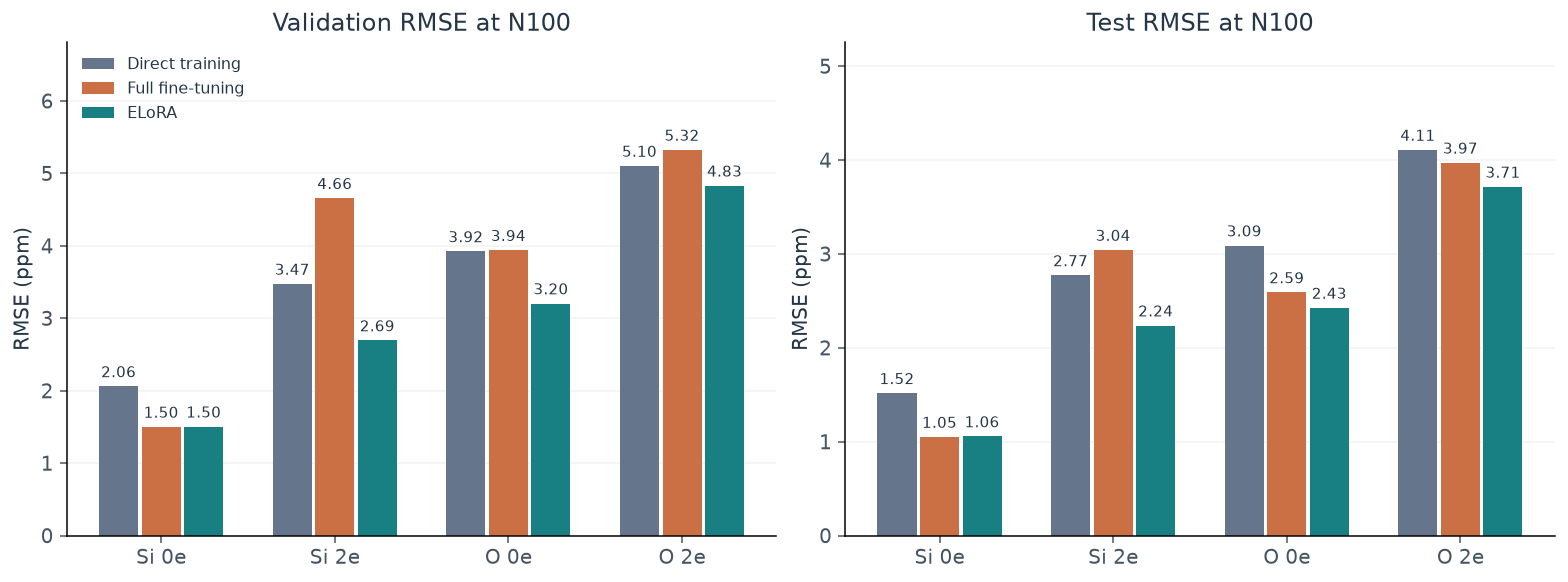

In [4]:
rows = []
for label in RUNS:
    for element, block in PANELS:
        selected = scores[(scores.Experiment == label) & (scores.Element == element) & (scores.Block == block)].set_index('Split')
        rows.append({'Method': LABELS[label], 'Element': element, 'Block': block,
            'Train RMSE': selected.loc['train', 'RMSE'], 'Validation RMSE': selected.loc['validation', 'RMSE'],
            'Test RMSE': selected.loc['test', 'RMSE'], 'Test MAE': selected.loc['test', 'MAE'], 'Test R²': selected.loc['test', 'R2']})
display(pd.DataFrame(rows))
fig = plot_error_comparison(DATA)
save_figure(fig, FIGURES, 'validation-test-rmse')
plt.show()


## Higher-order output parity

All five signed `2e` coefficients are included for every Si or O atom in the 150 test structures. Panels share limits across methods. The checkpoint choice is the same as for validation; no fitting is performed on the test set.

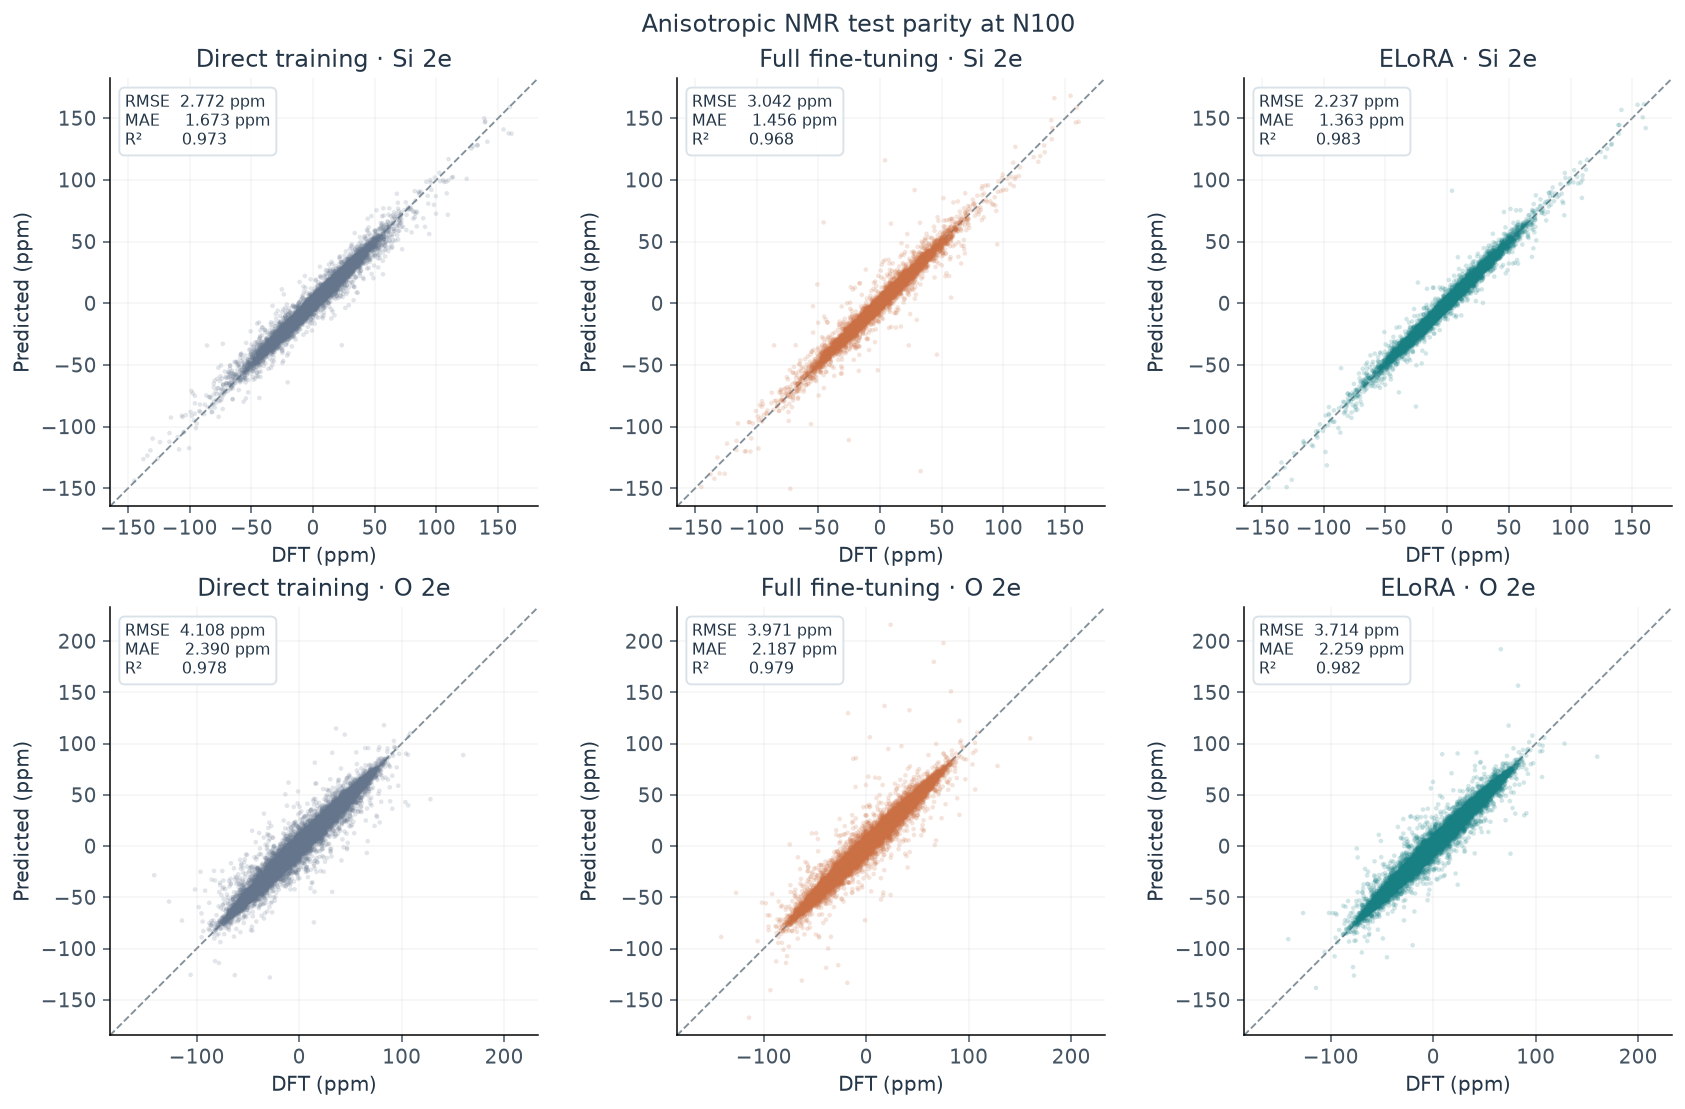

In [5]:
fig = plot_anisotropic_parity(DATA, 'test')
save_figure(fig, FIGURES, 'test-anisotropic-parity')
plt.show()


## Anisotropic component errors

The pooled `2e` score can be resolved into the RMSE of its five coefficients. ELoRA improves all five test components for both elements. Full fine-tuning improves Si q₄ but worsens the other four; its Si q₃ RMSE is 3.340 ppm, versus 2.813 for direct training and 2.284 for ELoRA. These components refer to the stored coordinate frame.

[Component analysis notebook](SymmetricTensor-N100-Anisotropic-Components.ipynb) adds Cartesian RMSE heatmaps, signed biases and an outlier-concentration view. For full fine-tuning’s Si q₃, the worst 1% of atom predictions contribute 70.9% of its squared error.

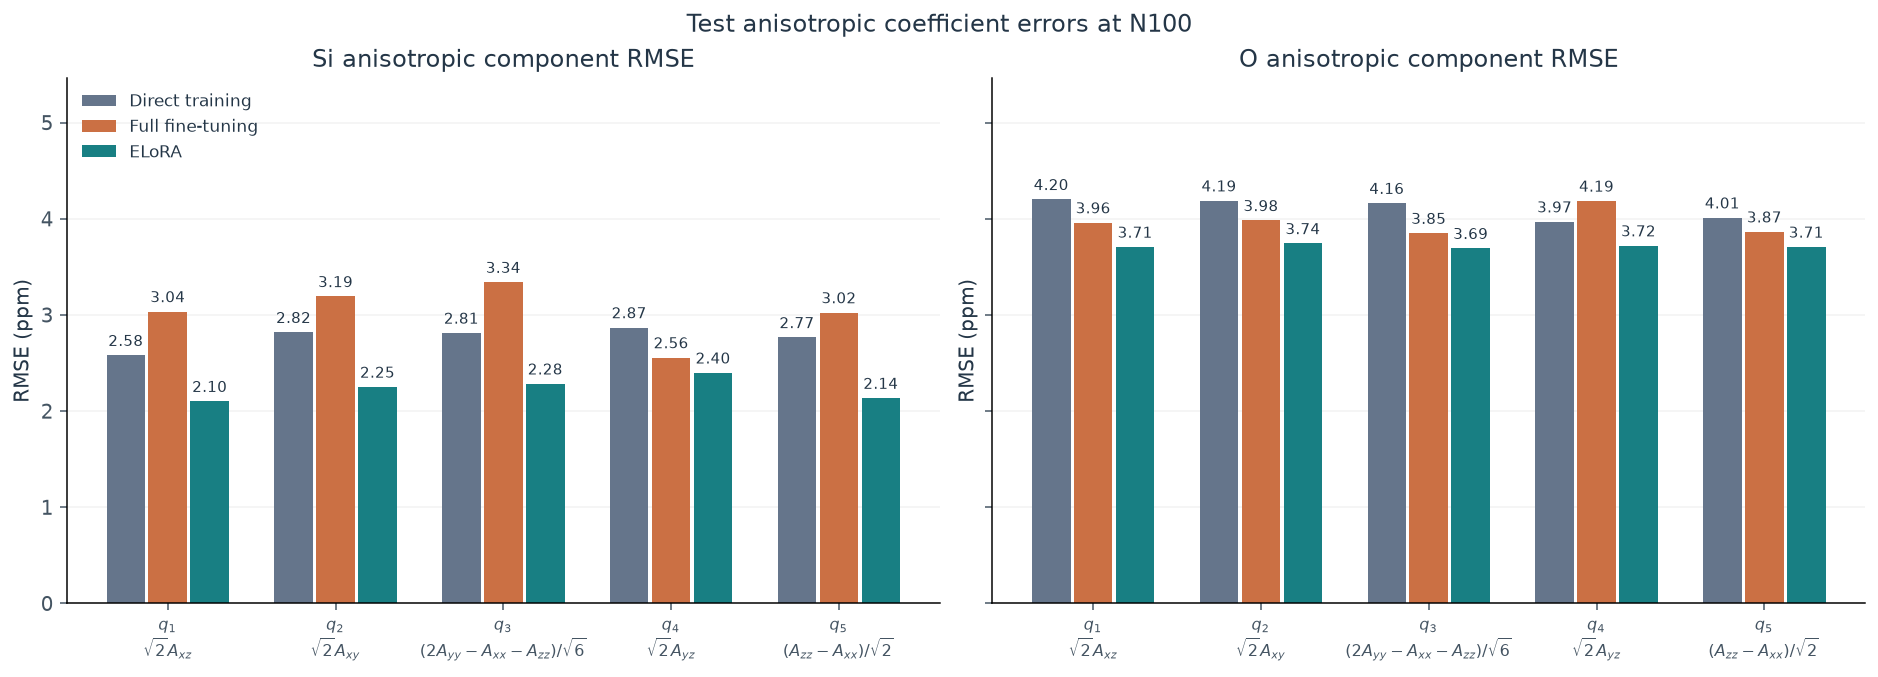

In [8]:
from analysis_helpers.anisotropic_components import load_components, prepare_components, plot_component_rmse
if RECOMPUTE:
    prepare_components(ROOT)
component_metrics, cartesian_component_metrics = load_components(ROOT)
COMPONENT_FIGURES = DATA / 'anisotropic-components/figures'
fig = plot_component_rmse(component_metrics, 'test')
save_figure(fig, COMPONENT_FIGURES, 'test-coefficient-rmse')
plt.show()


## Tensor error and paired comparison

The Frobenius error includes all tensor components in an orthonormal basis. Anisotropic skill is 1 − SSE(model)/SSE(zero anisotropy), a rotation-invariant check against predicting no anisotropy. The paired bootstrap resamples entire test structures, retaining all atoms/components within each structure. Its interval is conditional on these fitted models and this stored split; it does not account for random-seed variability or correlated parent trajectories.

In [6]:
tensor_scores = pd.read_csv(DATA / 'tensor-metrics.csv', dtype={'Experiment': str})
display(tensor_scores[tensor_scores.Split == 'test'].drop(columns=['Experiment', 'Split']).reset_index(drop=True))
display(pd.read_csv(DATA / 'test-bootstrap.csv', dtype={'Experiment': str}).assign(
    Method=lambda frame: frame.Experiment.map(LABELS)).drop(columns='Experiment'))


,Method,Element,Full tensor Frobenius RMSE,Anisotropic Frobenius RMSE,Anisotropic relative RMS error,Anisotropic skill versus zero
0,Direct training,Si,6.7311,6.1976,0.1633,0.9733
1,Direct training,O,10.6303,9.1852,0.1483,0.9780
2,Full fine-tuning,Si,7.0401,6.8011,0.1792,0.9679
3,Full fine-tuning,O,9.9476,8.8786,0.1433,0.9795
4,ELoRA,Si,5.3259,5.0018,0.1318,0.9826
5,ELoRA,O,9.3072,8.3054,0.1341,0.9820


,Element,Block,RMSE reduction versus direct (%),95% structure-bootstrap lower (%),95% structure-bootstrap upper (%),Method
0,Si,iso,30.7479,23.6068,35.6937,Full fine-tuning
1,Si,iso,30.3411,25.4036,34.1763,ELoRA
2,Si,aniso,-9.7388,-34.0794,14.5344,Full fine-tuning
3,Si,aniso,19.2945,13.1838,24.1178,ELoRA
4,O,iso,16.1648,11.6216,20.4707,Full fine-tuning
5,O,iso,21.5029,16.0097,25.8796,ELoRA
6,O,aniso,3.3378,-4.8667,11.3793,Full fine-tuning
7,O,aniso,9.5777,6.8092,12.2727,ELoRA


## Changes to the transferred representations

The E/F source has final `128x0e + 128x2e` channels. Its energy readout uses scalar channels and squared norms of the `2e` channels, giving those higher-order features an E/F training gradient. NMR uses a fresh equivariant readout to recover signed tensor components.

On all 50 validation structures, compare each adapted layer with the corrected E/F layer in the shared initial channel coordinates. Relative RMS change is ||h_NMR − h_E/F|| / ||h_E/F||, pooled over atoms and components separately for Si/O and `0e`/`2e`. The original ELoRA backbone state is checked bit-for-bit against the source; its adapters nevertheless change the actual features. Two `0o` adapter blocks remain zero because those channels cannot reach the pruned final `0e + 2e` output; all 12 adapted operators have nonzero updates through other paths. This diagnostic measures how much representations moved. Channel rescaling and mixing can change it, so a larger or smaller value is not an accuracy or transfer-quality score. Final `2e` feature RMS grows about 26–36 times in full fine-tuning and about 16 times in ELoRA. These large amplitude changes dominate the raw RMS-distance statistic; the cosine similarity is also reported to separate amplitude from pattern changes.

,Method,Element,Irrep,Relative RMS feature change,Cosine similarity,Feature RMS ratio
0,Full fine-tuning,Si,0e,11.3948,-0.3983,10.9595
1,Full fine-tuning,O,0e,5.9923,0.4946,6.4236
2,Full fine-tuning,Si,2e,26.1708,0.1468,26.2989
3,Full fine-tuning,O,2e,36.2957,0.1556,36.4378
4,ELoRA,Si,0e,4.0632,0.0221,3.9604
5,ELoRA,O,0e,3.8621,0.6116,4.3918
6,ELoRA,Si,2e,15.2049,0.4750,15.6544
7,ELoRA,O,2e,15.1228,0.4707,15.5677


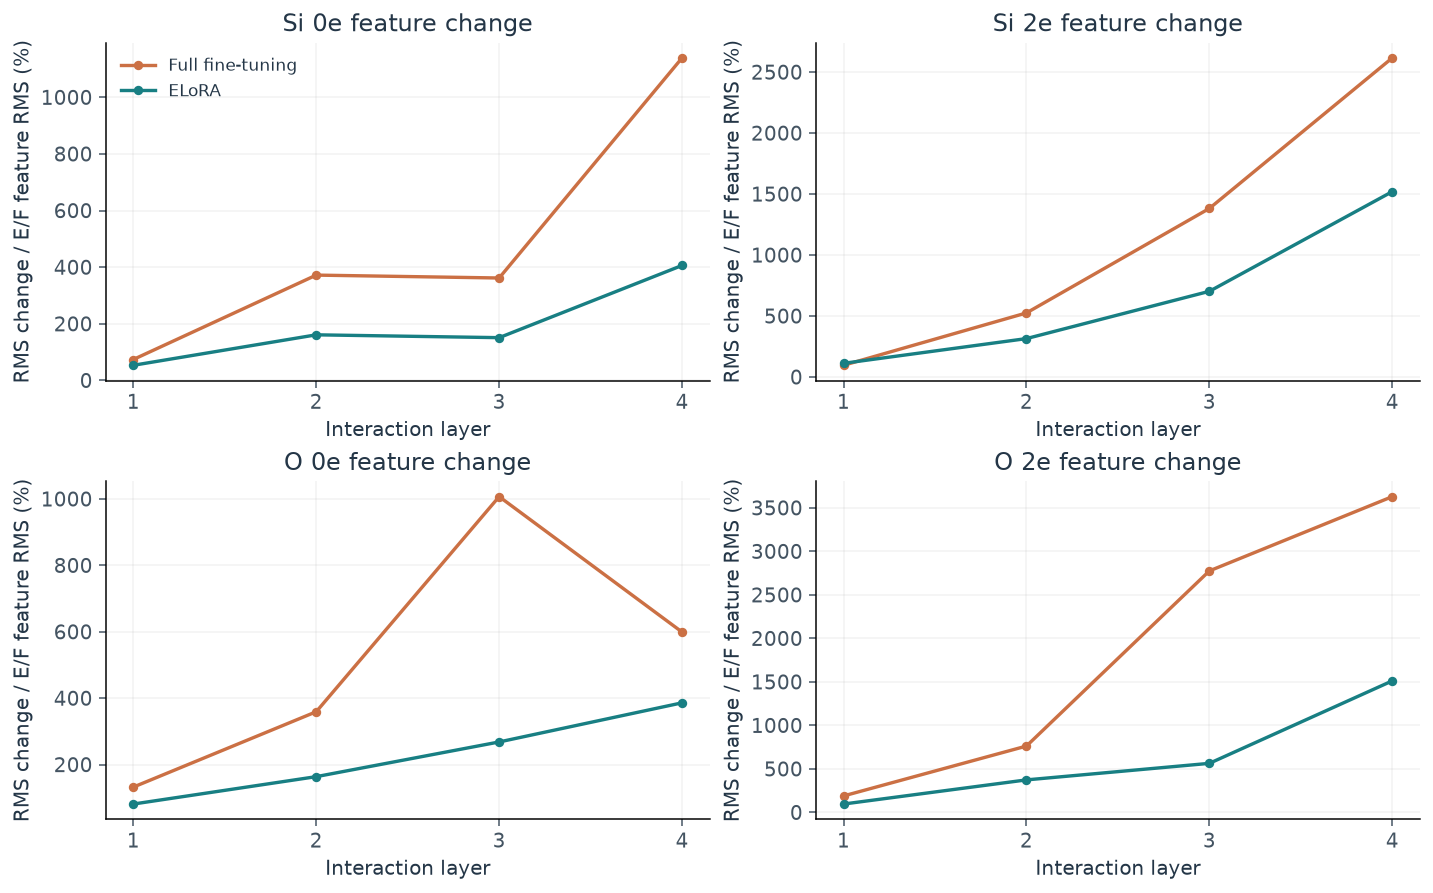

,operation,path_index,input_irrep,output_irrep,path_shape
0,layers.2.post_message_linear,0,0o,0o,"[256, 128]"
1,layers.3.pre_message_linear,0,0o,0o,"[128, 128]"


ELoRA original backbone unchanged: True
All 12 adapter operators have learned nonzero updates: True


In [7]:
feature_changes = pd.read_csv(DATA / 'feature-change.csv', dtype={'Experiment': str})
display(feature_changes[feature_changes.Layer == 4][
    ['Method', 'Element', 'Irrep', 'Relative RMS feature change', 'Cosine similarity', 'Feature RMS ratio']].reset_index(drop=True))
fig = plot_feature_change(DATA)
save_figure(fig, FIGURES, 'feature-changes')
plt.show()
print('ELoRA original backbone unchanged:', audits['06']['original_backbone_state_exactly_matches_source'])
print('All 12 adapter operators have learned nonzero updates:', audits['06']['all_adapter_operators_have_nonzero_updates'])
display(pd.DataFrame(audits['06']['zero_adapter_blocks']))


## Interpretation and next discriminating experiment

**ELoRA has the lowest balanced held-out test loss (0.015898).** Full fine-tuning: Si anisotropic RMSE is 9.7% higher than direct training; O anisotropic RMSE is 3.3% lower than direct training. ELoRA: Si anisotropic RMSE is 19.3% lower than direct training; O anisotropic RMSE is 9.6% lower than direct training.

Use the tables and held-out `2e` parity to assess tensor prediction separately from scalar shielding. Full fine-tuning has a marginally lower Si isotropic test RMSE than ELoRA (1.050 versus 1.056 ppm); ELoRA has lower test RMSE in the other three groups. The MAE rankings also differ for some groups, so there is no universal winner for every error statistic. ELoRA and full fine-tuning transfer and adapt higher-order channels, so improved `2e` generalisation is evidence consistent with useful transfer in the complete recipe. It does not isolate how much useful NMR information was already present in the frozen E/F features. Different learning rates and a single seed also limit general claims about the methods.

The direct next test of pre-existing higher-order feature utility is a frozen-backbone NMR readout probe, comparing the corrected E/F backbone with a frozen random-backbone control on the same N100 data. Repeat seeds, then assess the `2e` outputs separately. That would distinguish useful pretrained tensor features from improvements created during NMR adaptation.